In [1]:
import numpy as np
import pandas as pd
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision.datasets import CIFAR10
from torchvision import transforms
from torch.utils.data import Subset
import matplotlib.pyplot as plt
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import classification_report
import torchvision.models as models
import random
import math
import torchvision.models as models
from torchvision.transforms import InterpolationMode
from torch.optim import lr_scheduler
import kagglehub
import os
from sklearn.model_selection import train_test_split
from PIL import Image
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from torchvision import tv_tensors
import torch.optim.lr_scheduler as lr_scheduler
from torchvision.transforms import v2
import copy
import os

# import torch_xla.distributed.parallel_loader as pl
# import torch_xla.debug.metrics as met
# import torch_xla.core.xla_model as xm
# import torch_xla

In [2]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu'
device

'cuda'

In [3]:
# device = torch_xla.device()
# device

# Задание 1. CNN локализация лицевых точек

In [4]:
path = '/kaggle/input/datasets/slnkvdns/facial-keypoints-detection/training.csv'
df = pd.read_csv(path)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7049 entries, 0 to 7048
Data columns (total 31 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   left_eye_center_x          7039 non-null   float64
 1   left_eye_center_y          7039 non-null   float64
 2   right_eye_center_x         7036 non-null   float64
 3   right_eye_center_y         7036 non-null   float64
 4   left_eye_inner_corner_x    2271 non-null   float64
 5   left_eye_inner_corner_y    2271 non-null   float64
 6   left_eye_outer_corner_x    2267 non-null   float64
 7   left_eye_outer_corner_y    2267 non-null   float64
 8   right_eye_inner_corner_x   2268 non-null   float64
 9   right_eye_inner_corner_y   2268 non-null   float64
 10  right_eye_outer_corner_x   2268 non-null   float64
 11  right_eye_outer_corner_y   2268 non-null   float64
 12  left_eyebrow_inner_end_x   2270 non-null   float64
 13  left_eyebrow_inner_end_y   2270 non-null   float

In [5]:
class FacialKeypointsDetectionDataset:
    def __init__(self, df, transforms, is_train):
        self.transforms = transforms
        if is_train:
            self.df = df.fillna(-1)
        else:
            self.df = df.fillna(-1)

    def __len__(self):
        return self.df.shape[0]

    def __getitem__(self, idx):
        target = torch.tensor(self.df.iloc[idx, :-1].to_numpy().astype('float32'))
        coords = target.reshape((-1, 2))
        
        mask = (coords != -1).unsqueeze(0)

        str_img = self.df.iloc[idx, -1]
        img = np.array(str_img.split()).astype('uint8').reshape(96, 96)
        img = np.stack([img] * 3, axis=-1)
        img = Image.fromarray(img)
        
        coords = tv_tensors.KeyPoints(coords.unsqueeze(0), canvas_size=(96, 96))

        transformed_img, transformed_coords = self.transforms(img, coords)
        transformed_coords /= transformed_img.shape[1]
        transformed_coords[~mask] = -1.0

        transformed_coords = transformed_coords.reshape(-1)

        return transformed_img, transformed_coords

In [6]:
def draw_example(img, target):
    x = target[range(0, 30, 2)]
    y = target[range(1, 30, 2)]

    plt.imshow(img)
    for i in range(15):
        if x[i] != -1 and y[i] != -1:
            plt.scatter(x[i] * img.shape[1], y[i] * img.shape[1], c='red')

def dataset_img_to_normal_img(dataset_img):
    img = dataset_img.numpy().transpose(1, 2, 0)
    img = std * img + mean
    img = np.clip(img, 0, 1)
    return img

In [7]:
def masked_rmse_loss(y_pred, y_true):
    mask = (y_true != -1)
    mse = ((y_pred - y_true) ** 2)[mask].sum() / (mask.sum() + 1e-8)
    rmse = torch.sqrt(mse + 1e-8) 
    return rmse

def masked_mse_loss(y_pred, y_true):
    mask = (y_true != -1)
    mse = ((y_pred - y_true) ** 2)[mask].sum() / (mask.sum() + 1e-8)
    return mse 

In [8]:
def train_loop(model, loss, optimizer, dataloader, train_losses, train_rmse, scheduler=None, verbose=None):
    model.train()

    batch_size = dataloader.batch_size
    all_targets = []
    all_predictions = []

    is_xla = 'xla' in str(device)
    loader = pl.MpDeviceLoader(dataloader, device) if is_xla else dataloader


    if verbose is not None:
        ver = len(dataloader) / verbose
    else:
        ver = 10

    for batch, (X, y) in enumerate(loader):
        X, y = X.to(device), y.to(device)

        optimizer.zero_grad()
        y_pred = model(X)
        output = loss(y_pred, y)
        
        output.backward()
        
        if is_xla:
            xm.optimizer_step(optimizer)
        else:
            optimizer.step()

        all_predictions.append(y_pred.detach().cpu())
        all_targets.append(y.detach().cpu())
        
        if (batch + 1) % int(ver) == 0:
            current_loss = output.detach().cpu().item()
            print(f'{(batch + 1) * batch_size}/{len(dataloader) * batch_size} | loss: {current_loss}')

            if scheduler:
                scheduler.step()
                
    all_predictions = torch.vstack(all_predictions)
    all_targets = torch.vstack(all_targets)

    train_avg_loss = loss(all_predictions, all_targets)
    train_losses.append(train_avg_loss.item())
    train_rmse.append(masked_rmse_loss(all_predictions, all_targets).item())
    print(f'Train avg loss: {train_avg_loss}')

In [9]:
def test_loop(model, loss, dataloader, test_losses, test_rmse):
    model.eval()
    all_targets = []
    all_predictions = []

    is_xla = 'xla' in str(device)
    loader = pl.MpDeviceLoader(dataloader, device) if is_xla else dataloader

    with torch.no_grad():
        for batch, (X, y) in enumerate(loader):
            X, y = X.to(device), y.to(device)
    
            y_pred = model(X)
            
            output = loss(y_pred, y)
    
            all_predictions.append(y_pred.detach().cpu())
            all_targets.append(y.detach().cpu())

        all_predictions = torch.vstack(all_predictions)
        all_targets = torch.vstack(all_targets)

        if is_xla:
            torch_xla.sync()
        
        avg_loss = loss(all_predictions, all_targets)

        print(f'{"Test avg loss:":11} {avg_loss:.7f}')        
        
        mask = (all_targets != -1)
        all_predictions = all_predictions[mask]
        all_targets = all_targets[mask]

        print('Test metrics:')
        rmse = root_mean_squared_error(all_targets, all_predictions)
        print(f'RMSE: {rmse}')
        print(f'MSE: {mean_squared_error(all_targets, all_predictions)}')
        print(f'MAE: {mean_absolute_error(all_targets, all_predictions)}')
        print(f'MAPE: {mean_absolute_percentage_error(all_targets, all_predictions)}')

        test_losses.append(avg_loss.item())
        test_rmse.append(rmse)
        return avg_loss

In [10]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# EfficientNetb0 с разморозкой некоторых слоёв features (6-8) с аугментацией + AdamW + ReduceLROnPlateau

In [32]:
weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1
model = models.efficientnet_b0(weights=weights)

In [33]:
model.classifier

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)

In [34]:
for n, p in model.named_children():
    print(n, p)

features Sequential(
  (0): Conv2dNormActivation(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): SiLU(inplace=True)
  )
  (1): Sequential(
    (0): MBConv(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): SiLU(inplace=True)
        )
        (1): SqueezeExcitation(
          (avgpool): AdaptiveAvgPool2d(output_size=1)
          (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
          (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
          (activation): SiLU(inplace=True)
          (scale_activation): Sigmoid()
        )
        (2): Conv2dNormActivation(
          (0): Conv2d(32, 16, kernel_size=(1, 1), stride

In [7]:
regressinon_layers = nn.Sequential(
    #nn.Dropout(p=0.1, inplace=True),
    nn.Linear(in_features=1280, out_features=1000, bias=True),
    nn.SiLU(),
    #nn.Dropout(p=0.1),
    nn.Linear(1000, 512),
    nn.SiLU(),
    nn.Linear(512, 30)
)

In [8]:
model.classifier = regressinon_layers

In [9]:
for name, layer in model.named_parameters():
    if 'classifier' not in name:
        layer.requires_grad = False

In [10]:
for i in range(6, 9):
    for param in model.features[i].parameters():
        param.requires_grad = True

In [11]:
for name, param in list(model.named_parameters()):
    if param.requires_grad:
        print(name)

features.6.0.block.0.0.weight
features.6.0.block.0.1.weight
features.6.0.block.0.1.bias
features.6.0.block.1.0.weight
features.6.0.block.1.1.weight
features.6.0.block.1.1.bias
features.6.0.block.2.fc1.weight
features.6.0.block.2.fc1.bias
features.6.0.block.2.fc2.weight
features.6.0.block.2.fc2.bias
features.6.0.block.3.0.weight
features.6.0.block.3.1.weight
features.6.0.block.3.1.bias
features.6.1.block.0.0.weight
features.6.1.block.0.1.weight
features.6.1.block.0.1.bias
features.6.1.block.1.0.weight
features.6.1.block.1.1.weight
features.6.1.block.1.1.bias
features.6.1.block.2.fc1.weight
features.6.1.block.2.fc1.bias
features.6.1.block.2.fc2.weight
features.6.1.block.2.fc2.bias
features.6.1.block.3.0.weight
features.6.1.block.3.1.weight
features.6.1.block.3.1.bias
features.6.2.block.0.0.weight
features.6.2.block.0.1.weight
features.6.2.block.0.1.bias
features.6.2.block.1.0.weight
features.6.2.block.1.1.weight
features.6.2.block.1.1.bias
features.6.2.block.2.fc1.weight
features.6.2.blo

In [12]:
model.classifier

Sequential(
  (0): Linear(in_features=1280, out_features=1000, bias=True)
  (1): SiLU()
  (2): Linear(in_features=1000, out_features=512, bias=True)
  (3): SiLU()
  (4): Linear(in_features=512, out_features=30, bias=True)
)

In [13]:
model = model.to(device)

In [14]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Число параметров: {total_params}")

Число параметров: 5816450


In [21]:
aug_transform = v2.Compose([
    v2.ToImage(),
    v2.Resize(224, interpolation=InterpolationMode.BICUBIC),
    v2.RandomPerspective(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean, std)
])

In [22]:
df = pd.read_csv(path)
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['left_eye_inner_corner_x'].notna(), random_state=42)
aug_train_dataset = FacialKeypointsDetectionDataset(train_df, transforms=aug_transform, is_train=True)
aug_test_dataset = FacialKeypointsDetectionDataset(test_df, transforms=aug_transform, is_train=False)

In [23]:
batch_size = 128
train_dataloader = DataLoader(aug_train_dataset, batch_size, num_workers=2)
test_dataloader = DataLoader(aug_test_dataset, batch_size, num_workers=2)

In [24]:
num_epochs = 60

In [25]:
loss_fn = masked_mse_loss
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
scheduler = lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=3, min_lr=1e-7, threshold=1e-4)
train_losses = []
train_rmse = []
test_losses = []
test_rmse = []

In [26]:
best_model = None
best_rmse = float('inf')
for i in range(num_epochs):
    print(f'Epoch {i+1}')
    train_loop(model, loss_fn, optimizer, train_dataloader, train_losses, train_rmse, verbose=5)
    val_loss = test_loop(model, loss_fn, test_dataloader, test_losses, test_rmse)
    if test_rmse[-1] < best_rmse:
        best_rmse = test_rmse[-1]
        best_model = copy.deepcopy(model)
    scheduler.step(val_loss)
    print('-' * 30)

Epoch 1
1152/5760 | loss: 0.012555988505482674
2304/5760 | loss: 0.0048766848631203175
3456/5760 | loss: 0.003707825904712081
4608/5760 | loss: 0.002911243587732315
5760/5760 | loss: 0.0033248653635382652
Train avg loss: 0.020861972123384476
Test avg loss: 0.0026753
Test metrics:
RMSE: 0.05172377211846754
MSE: 0.00267534860216316
MAE: 0.03918047400874502
MAPE: 0.08483534841528591
------------------------------
Epoch 2
1152/5760 | loss: 0.0019269533222541213
2304/5760 | loss: 0.00244067027233541
3456/5760 | loss: 0.0017309415852651
4608/5760 | loss: 0.0018584198551252484
5760/5760 | loss: 0.0008896607905626297
Train avg loss: 0.0022103670053184032
Test avg loss: 0.0018758
Test metrics:
RMSE: 0.04331073743192699
MSE: 0.0018758199768973216
MAE: 0.03191491712133863
MAPE: 0.07120978237349897
------------------------------
Epoch 3
1152/5760 | loss: 0.0013258620165288448
2304/5760 | loss: 0.0019405948696658015
3456/5760 | loss: 0.0015711357118561864
4608/5760 | loss: 0.001665768213570118
5760

/tmp/ipykernel_57/3458791646.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  img = torch.tensor(img).unsqueeze(dim=0).to(device)


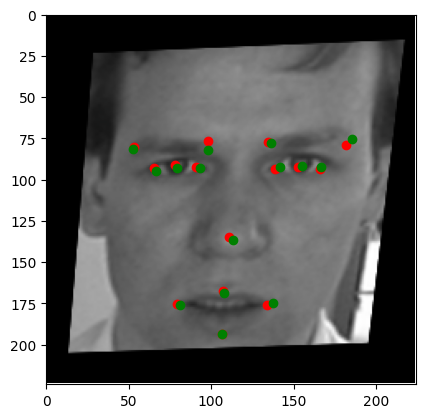

In [34]:
best_model.eval()
with torch.no_grad():
    idx = random.randint(0, len(aug_test_dataset))
    img, true_target = aug_test_dataset[idx]
    img_vis = dataset_img_to_normal_img(img)

    
    img = torch.tensor(img).unsqueeze(dim=0).to(device)
    pred_target = best_model(img).cpu().detach().numpy()

    draw_example(img_vis, pred_target[0])
    plt.imshow(img_vis)
    for i in range(0, 30, 2):
        x, y = true_target[i] * img.shape[2], true_target[i+1] * img.shape[2]
        if x != -1 and y != -1:
            plt.scatter(x, y, c='green')
    plt.xlim(0, 224)
    plt.ylim(224, 0)

In [35]:
torch.save(best_model.state_dict(), './efficientnet_b0_weights_1.pth')

In [36]:
idx = np.argmin(test_rmse)
train_rmse_1 = train_rmse[idx]
test_rmse_1 = test_rmse[idx]

In [37]:
print(f"Train rmse: {train_rmse_1}")
print(f"Test rmse: {test_rmse_1}")

Train rmse: 0.0209378469735384
Test rmse: 0.02334942542096105


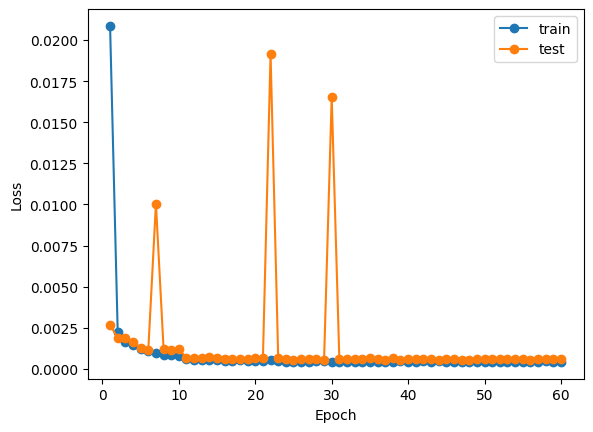

In [38]:
x = range(1, num_epochs + 1)
plt.plot(x, train_losses, label='train', marker='o')
plt.plot(x, test_losses, label='test', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# EfficientNetb3 без разморозки feature слоёв, AdamW, без аугментации, с lr schduler

In [15]:
weights = models.EfficientNet_B3_Weights.IMAGENET1K_V1
model = models.efficientnet_b3(weights=weights)

Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to C:\Users\Denis/.cache\torch\hub\checkpoints\efficientnet_b3_rwightman-b3899882.pth


100%|█████████████████████████████████████████████████████████████████████████████| 47.2M/47.2M [00:04<00:00, 10.6MB/s]


In [16]:
regressinon_layers = nn.Sequential(
    nn.Dropout(p=0.1),
    nn.Linear(in_features=1536 , out_features=1000, bias=True),
    nn.SiLU(),
    nn.Dropout(p=0.1),
    nn.Linear(1000, 512),
    nn.SiLU(),
    nn.Dropout(p=0.1),
    nn.Linear(512, 30)
)

In [17]:
model.classifier = regressinon_layers

In [18]:
for name, layer in model.named_parameters():
    if 'classifier' not in name:
        layer.requires_grad = False

In [19]:
for name, param in list(model.named_parameters()):
    if param.requires_grad:
        print(name)

classifier.1.weight
classifier.1.bias
classifier.4.weight
classifier.4.bias
classifier.7.weight
classifier.7.bias


In [20]:
model = model.to(device)

In [21]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Число параметров: {total_params}")

Число параметров: 12761134


In [41]:
transform = v2.Compose([
    v2.ToImage(),
    v2.Resize(320, interpolation=InterpolationMode.BICUBIC),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean, std)
])

In [42]:
df = pd.read_csv(path)
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['left_eye_inner_corner_x'].notna(), random_state=42)
train_dataset = FacialKeypointsDetectionDataset(train_df, transforms=transform, is_train=True)
test_dataset = FacialKeypointsDetectionDataset(test_df, transforms=transform, is_train=False)

In [43]:
batch_size = 256
train_dataloader = DataLoader(train_dataset, batch_size, num_workers=4, pin_memory=True)
test_dataloader = DataLoader(test_dataset, batch_size, num_workers=4, pin_memory=True)

In [44]:
num_epochs = 60

In [45]:
loss_fn = masked_mse_loss
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
scheduler = lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=5, min_lr=1e-7, threshold=1e-4)
train_losses = []
train_rmse = []
test_losses = []
test_rmse = []

In [46]:
best_model = None
best_rmse = float('inf')
for i in range(num_epochs):
    print(f'Epoch {i+1}')
    train_loop(model, loss_fn, optimizer, train_dataloader, train_losses, train_rmse, verbose=5)
    val_loss = test_loop(model, loss_fn, test_dataloader, test_losses, test_rmse)
    scheduler.step(val_loss)
    if test_rmse[-1] < best_rmse:
        best_rmse = test_rmse[-1]
        best_model = copy.deepcopy(model)
    print('-' * 30)

Epoch 1
1024/5888 | loss: 0.10179474204778671
2048/5888 | loss: 0.04917451739311218
3072/5888 | loss: 0.018965061753988266
4096/5888 | loss: 0.009204850532114506
5120/5888 | loss: 0.010372122749686241
Train avg loss: 0.04672010615468025
Test avg loss: 0.2745968
Test metrics:
RMSE: 0.5240198374659657
MSE: 0.27459679005785714
MAE: 0.36463271644957274
MAPE: 0.7169002974545998
------------------------------
Epoch 2
1024/5888 | loss: 0.005102207884192467
2048/5888 | loss: 0.004239640198647976
3072/5888 | loss: 0.0036696186289191246
4096/5888 | loss: 0.004024419002234936
5120/5888 | loss: 0.010964795015752316
Train avg loss: 0.004809220787137747
Test avg loss: 0.1922484
Test metrics:
RMSE: 0.4384614174127358
MSE: 0.19224841455958536
MAE: 0.2469389286557052
MAPE: 0.48562618911513905
------------------------------
Epoch 3
1024/5888 | loss: 0.0035827315878123045
2048/5888 | loss: 0.0028413119725883007
3072/5888 | loss: 0.0029808487743139267
4096/5888 | loss: 0.0037578402552753687
5120/5888 | lo

/tmp/ipykernel_57/1406329778.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  img = torch.tensor(img).unsqueeze(dim=0).to(device)


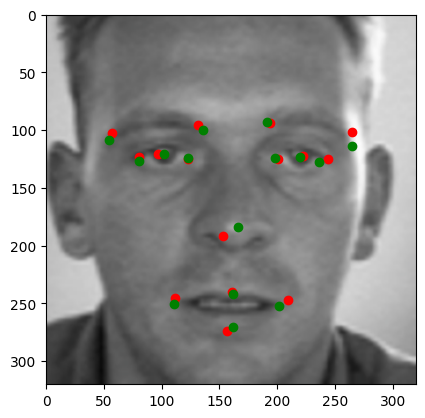

In [49]:
best_model.eval()
with torch.no_grad():
    idx = random.randint(0, len(test_dataset))
    img, true_target = test_dataset[idx]
    img_vis = dataset_img_to_normal_img(img)

    
    img = torch.tensor(img).unsqueeze(dim=0).to(device)
    pred_target = best_model(img).cpu().detach().numpy()

    draw_example(img_vis, pred_target[0])
    plt.imshow(img_vis)
    for i in range(0, 30, 2):
        x, y = true_target[i] * img.shape[2], true_target[i+1] * img.shape[2]
        if x != -1 and y != -1:
            plt.scatter(x, y, c='green')
    plt.xlim(0, 320)
    plt.ylim(320, 0)

In [50]:
torch.save(best_model.state_dict(), './efficientnet_b3_weights_2.pth')

In [51]:
idx = np.argmin(test_rmse)
train_rmse_2 = train_rmse[idx]
test_rmse_2 = test_rmse[idx]

In [52]:
print(f"Train rmse: {train_rmse_2}")
print(f"Test rmse: {test_rmse_2}")

Train rmse: 0.0391613207757473
Test rmse: 0.03462276740236234


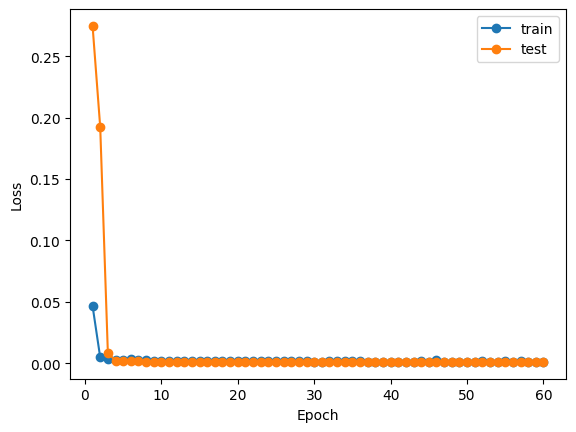

In [53]:
x = range(1, num_epochs + 1)
plt.plot(x, train_losses, label='train', marker='o')
plt.plot(x, test_losses, label='test', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Custom model + Adam + BatchNorm + CosineAnnealingLR

In [22]:
class CustomModel(nn.Module):
    def __init__(self, h=96, w=96):
        super().__init__()
        self.conv_stack = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.SiLU(),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.SiLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.SiLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(128 * h//2 * w//2, 512),
            nn.SiLU(),
            nn.Linear(512, 512),
            nn.SiLU(),
            nn.Linear(512, 30)
        )

    def forward(self, x):
        x = self.conv_stack(x)
        x = self.flatten(x)
        x = self.linear_relu_stack(x)
        return x

In [23]:
my_model = CustomModel().to(device)

In [24]:
total_params = sum(p.numel() for p in my_model.parameters())
print(f"Число параметров: {total_params}")

Число параметров: 151497374


In [12]:
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean, std)
])

In [13]:
df = pd.read_csv(path)
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['left_eye_inner_corner_x'].notna(), random_state=42)
train_dataset = FacialKeypointsDetectionDataset(train_df, transforms=transform, is_train=True)
test_dataset = FacialKeypointsDetectionDataset(test_df, transforms=transform, is_train=False)

In [14]:
batch_size = 256
train_dataloader = DataLoader(train_dataset, batch_size, num_workers=4, pin_memory=True)
test_dataloader = DataLoader(test_dataset, batch_size, num_workers=4, pin_memory=True)

In [15]:
num_epochs = 60

In [ ]:
loss_fn = masked_mse_loss
optimizer = torch.optim.Adam(my_model.parameters(), lr=1e-3)
scheduler = lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
train_losses = []
test_losses = []
train_rmse = []
test_rmse = []

In [22]:
best_model = None
best_rmse = float('inf')
for i in range(num_epochs):
    print(f'Epoch {i+1}')
    train_loop(my_model, loss_fn, optimizer, train_dataloader, train_losses, train_rmse, verbose=5)
    val_loss = test_loop(my_model, loss_fn, test_dataloader, test_losses, test_rmse)
    scheduler.step()
    if test_rmse[-1] < best_rmse:
        best_rmse = test_rmse[-1]
        best_model = copy.deepcopy(my_model)
    print('-' * 30)

Epoch 1
1024/5888 | loss: 214.04774475097656
2048/5888 | loss: 35.665653228759766
3072/5888 | loss: 18.636444091796875
4096/5888 | loss: 11.730213165283203
5120/5888 | loss: 6.910699844360352
Train avg loss: 171.17343139648438
Test avg loss: 4.1425109
Test metrics:
RMSE: 2.035315793794651
MSE: 4.14251038046995
MAE: 1.4558951682594727
MAPE: 3.5898471860981243
------------------------------
Epoch 2
1024/5888 | loss: 2.617526054382324
2048/5888 | loss: 1.8749192953109741
3072/5888 | loss: 1.110463261604309
4096/5888 | loss: 0.7807247638702393
5120/5888 | loss: 0.5128929018974304
Train avg loss: 1.4433164596557617
Test avg loss: 0.3189791
Test metrics:
RMSE: 0.5647823283628389
MSE: 0.3189790784309496
MAE: 0.43994781980321757
MAPE: 1.0646071742863588
------------------------------
Epoch 3
1024/5888 | loss: 0.3199250102043152
2048/5888 | loss: 0.17559216916561127
3072/5888 | loss: 0.1867026537656784
4096/5888 | loss: 0.1331072896718979
5120/5888 | loss: 0.09898078441619873
Train avg loss: 0.

/tmp/ipykernel_57/2051153737.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  img = torch.tensor(img).unsqueeze(dim=0).to(device)


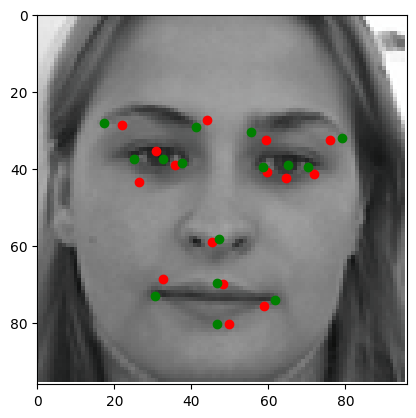

In [28]:
best_model.eval()
with torch.no_grad():
    idx = random.randint(0, len(test_dataset))
    img, true_target = test_dataset[idx]
    img_vis = dataset_img_to_normal_img(img)

    
    img = torch.tensor(img).unsqueeze(dim=0).to(device)
    pred_target = best_model(img).cpu().detach().numpy()

    draw_example(img_vis, pred_target[0])
    plt.imshow(img_vis)
    for i in range(0, 30, 2):
        x, y = true_target[i] * img.shape[2], true_target[i+1] * img.shape[2]
        if x != -1 and y != -1:
            plt.scatter(x, y, c='green')
    plt.xlim(0, 96)
    plt.ylim(96, 0)

In [29]:
torch.save(best_model.state_dict(), './custom_model_weights_3.pth')

In [31]:
idx = np.argmin(test_rmse)
train_rmse_3 = train_rmse[idx]
test_rmse_3 = test_rmse[idx]

In [33]:
print(f"Train rmse: {train_rmse_3}")
print(f"Test rmse: {test_rmse_3}")

Train rmse: 0.04398193955421448
Test rmse: 0.050016746957805815


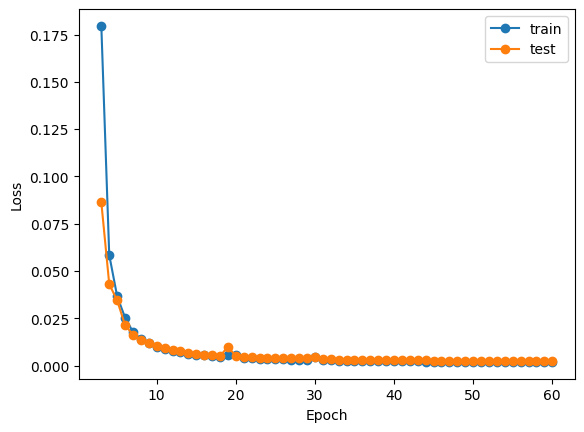

In [36]:
x = range(3, num_epochs + 1)
plt.plot(x, train_losses[2:], label='train', marker='o')
plt.plot(x, test_losses[2:], label='test', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Custom model + SGD (momentum = 0.9). Без Dropout, без BatchNorm, без LRScheduler.

In [25]:
class CustomModel_2(nn.Module):
    def __init__(self, h=96, w=96):
        super().__init__()
        self.conv_stack = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.SiLU(),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.SiLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.SiLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(128 * h//2 * w//2, 512),
            nn.SiLU(),
            nn.Linear(512, 512),
            nn.SiLU(),
            nn.Linear(512, 30)
        )

    def forward(self, x):
        x = self.conv_stack(x)
        x = self.flatten(x)
        x = self.linear_relu_stack(x)
        return x

In [26]:
my_model = CustomModel_2().to(device)

In [28]:
total_params = sum(p.numel() for p in my_model.parameters())
print(f"Число параметров: {total_params}")

Число параметров: 151496734


In [12]:
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean, std)
])

In [13]:
df = pd.read_csv(path)
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['left_eye_inner_corner_x'].notna(), random_state=42)
train_dataset = FacialKeypointsDetectionDataset(train_df, transforms=transform, is_train=True)
test_dataset = FacialKeypointsDetectionDataset(test_df, transforms=transform, is_train=False)

In [14]:
batch_size = 256
train_dataloader = DataLoader(train_dataset, batch_size, num_workers=4, pin_memory=True)
test_dataloader = DataLoader(test_dataset, batch_size, num_workers=4, pin_memory=True)

In [15]:
num_epochs = 60

In [ ]:
loss_fn = masked_mse_loss
optimizer = torch.optim.SGD(my_model.parameters(), lr=1e-2, momentum=0.9)
train_losses = []
test_losses = []
train_rmse = []
test_rmse = []

In [21]:
best_model = None
best_rmse = float('inf')
for i in range(num_epochs):
    print(f'Epoch {i+1}')
    train_loop(my_model, loss_fn, optimizer, train_dataloader, train_losses, train_rmse, verbose=5)
    val_loss = test_loop(my_model, loss_fn, test_dataloader, test_losses, test_rmse)
    if test_rmse[-1] < best_rmse:
        best_rmse = test_rmse[-1]
        best_model = copy.deepcopy(my_model)
    print('-' * 30)

Epoch 1
1024/5888 | loss: 0.28609710931777954
2048/5888 | loss: 0.26833614706993103
3072/5888 | loss: 0.24279847741127014
4096/5888 | loss: 0.21026089787483215
5120/5888 | loss: 0.16344279050827026
Train avg loss: 0.2352387011051178
Test avg loss: 0.1128764
Test metrics:
RMSE: 0.3359709012745001
MSE: 0.11287644650319986
MAE: 0.2856298748090426
MAPE: 0.5662826974053694
------------------------------
Epoch 2
1024/5888 | loss: 0.10886289924383163
2048/5888 | loss: 0.059515174478292465
3072/5888 | loss: 0.04484646022319794
4096/5888 | loss: 0.03125859424471855
5120/5888 | loss: 0.01970865949988365
Train avg loss: 0.05551533028483391
Test avg loss: 0.0141140
Test metrics:
RMSE: 0.11880254559111923
MSE: 0.014114044838929965
MAE: 0.08821887252868132
MAPE: 0.18237394373852817
------------------------------
Epoch 3
1024/5888 | loss: 0.011165212839841843
2048/5888 | loss: 0.00899755023419857
3072/5888 | loss: 0.009304739534854889
4096/5888 | loss: 0.008992386981844902
5120/5888 | loss: 0.0064901

/tmp/ipykernel_57/2051153737.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  img = torch.tensor(img).unsqueeze(dim=0).to(device)


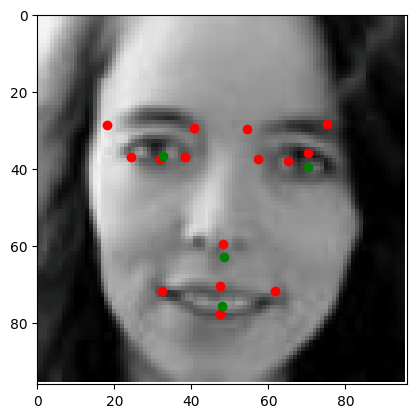

In [27]:
best_model.eval()
with torch.no_grad():
    idx = random.randint(0, len(test_dataset))
    img, true_target = test_dataset[idx]
    img_vis = dataset_img_to_normal_img(img)

    
    img = torch.tensor(img).unsqueeze(dim=0).to(device)
    pred_target = best_model(img).cpu().detach().numpy()

    draw_example(img_vis, pred_target[0])
    plt.imshow(img_vis)
    for i in range(0, 30, 2):
        x, y = true_target[i] * img.shape[2], true_target[i+1] * img.shape[2]
        if x != -1 and y != -1:
            plt.scatter(x, y, c='green')
    plt.xlim(0, 96)
    plt.ylim(96, 0)

In [28]:
torch.save(best_model.state_dict(), './custom_model_weights_4.pth')

In [29]:
idx = np.argmin(test_rmse)
train_rmse_4 = train_rmse[idx]
test_rmse_4 = test_rmse[idx]

In [30]:
print(f"Train rmse: {train_rmse_4}")
print(f"Test rmse: {test_rmse_4}")

Train rmse: 0.03460710868239403
Test rmse: 0.03503682027347692


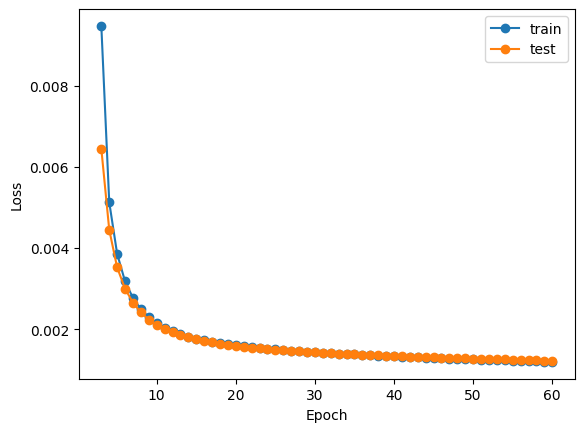

In [31]:
x = range(3, num_epochs + 1)
plt.plot(x, train_losses[2:], label='train', marker='o')
plt.plot(x, test_losses[2:], label='test', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Custom model + Adam. Без Dropout, без BatchNorm, без LRScheduler.

In [29]:
class CustomModel_2(nn.Module):
    def __init__(self, h=96, w=96):
        super().__init__()
        self.conv_stack = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.SiLU(),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.SiLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.SiLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(128 * h//2 * w//2, 512),
            nn.SiLU(),
            nn.Linear(512, 512),
            nn.SiLU(),
            nn.Linear(512, 30)
        )

    def forward(self, x):
        x = self.conv_stack(x)
        x = self.flatten(x)
        x = self.linear_relu_stack(x)
        return x

In [30]:
my_model = CustomModel_2().to(device)

In [31]:
total_params = sum(p.numel() for p in my_model.parameters())
print(f"Число параметров: {total_params}")

Число параметров: 151496734


In [12]:
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean, std)
])

In [13]:
df = pd.read_csv(path)
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['left_eye_inner_corner_x'].notna(), random_state=42)
train_dataset = FacialKeypointsDetectionDataset(train_df, transforms=transform, is_train=True)
test_dataset = FacialKeypointsDetectionDataset(test_df, transforms=transform, is_train=False)

In [14]:
batch_size = 256
train_dataloader = DataLoader(train_dataset, batch_size, num_workers=4, pin_memory=True)
test_dataloader = DataLoader(test_dataset, batch_size, num_workers=4, pin_memory=True)

In [15]:
num_epochs = 60

In [ ]:
loss_fn = masked_mse_loss
optimizer = torch.optim.Adam(my_model.parameters(), lr=1e-3)
train_losses = []
test_losses = []
train_rmse = []
test_rmse = []

In [17]:
best_model = None
best_rmse = float('inf')
for i in range(num_epochs):
    print(f'Epoch {i+1}')
    train_loop(my_model, loss_fn, optimizer, train_dataloader, train_losses, train_rmse, verbose=5)
    val_loss = test_loop(my_model, loss_fn, test_dataloader, test_losses, test_rmse)
    if test_rmse[-1] < best_rmse:
        best_rmse = test_rmse[-1]
        best_model = copy.deepcopy(my_model)
    print('-' * 30)

Epoch 1
1024/5888 | loss: 1.7278200387954712
2048/5888 | loss: 0.0981745719909668
3072/5888 | loss: 0.3642940819263458
4096/5888 | loss: 0.052702050656080246
5120/5888 | loss: 0.01686028577387333
Train avg loss: 0.33167901635169983
Test avg loss: 0.0136321
Test metrics:
RMSE: 0.11675653469641491
MSE: 0.013632088394315138
MAE: 0.08646479096169478
MAPE: 0.19055120367370468
------------------------------
Epoch 2
1024/5888 | loss: 0.010167192667722702
2048/5888 | loss: 0.0068437280133366585
3072/5888 | loss: 0.005295049864798784
4096/5888 | loss: 0.0034185261465609074
5120/5888 | loss: 0.003228485118597746
Train avg loss: 0.005892111454159021
Test avg loss: 0.0024933
Test metrics:
RMSE: 0.049932769231572194
MSE: 0.0024932814431334427
MAE: 0.0368527707332312
MAPE: 0.0822332159354798
------------------------------
Epoch 3
1024/5888 | loss: 0.0023054759949445724
2048/5888 | loss: 0.0019710927736014128
3072/5888 | loss: 0.0019073168514296412
4096/5888 | loss: 0.0016119431238621473
5120/5888 | 

/tmp/ipykernel_57/2051153737.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  img = torch.tensor(img).unsqueeze(dim=0).to(device)


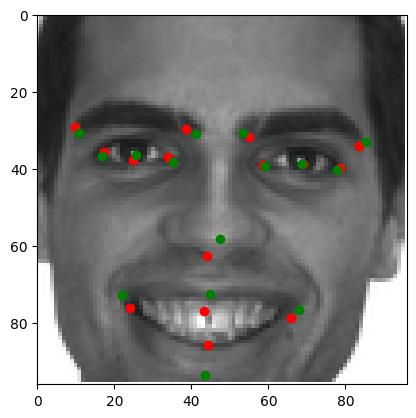

In [18]:
best_model.eval()
with torch.no_grad():
    idx = random.randint(0, len(test_dataset))
    img, true_target = test_dataset[idx]
    img_vis = dataset_img_to_normal_img(img)

    
    img = torch.tensor(img).unsqueeze(dim=0).to(device)
    pred_target = best_model(img).cpu().detach().numpy()

    draw_example(img_vis, pred_target[0])
    plt.imshow(img_vis)
    for i in range(0, 30, 2):
        x, y = true_target[i] * img.shape[2], true_target[i+1] * img.shape[2]
        if x != -1 and y != -1:
            plt.scatter(x, y, c='green')
    plt.xlim(0, 96)
    plt.ylim(96, 0)

In [19]:
torch.save(best_model.state_dict(), './custom_model_weights_5.pth')

In [20]:
idx = np.argmin(test_rmse)
train_rmse_5 = train_rmse[idx]
test_rmse_5 = test_rmse[idx]

In [21]:
print(f"Train rmse: {train_rmse_5}")
print(f"Test rmse: {test_rmse_5}")

Train rmse: 0.021106140688061714
Test rmse: 0.02876311595482574


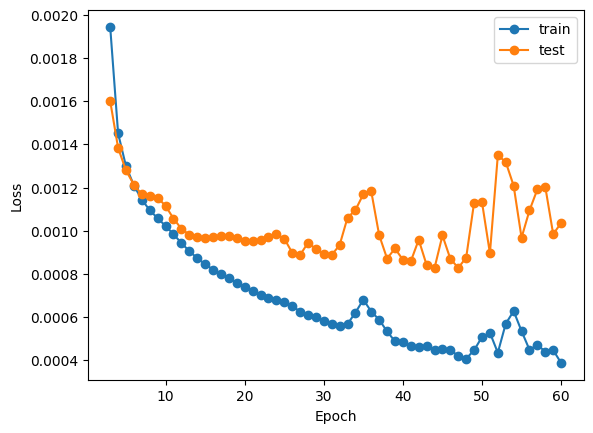

In [22]:
x = range(3, num_epochs + 1)
plt.plot(x, train_losses[2:], label='train', marker='o')
plt.plot(x, test_losses[2:], label='test', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Визуализация слоёв (кастомной модели)

In [77]:
def visualize_conv(layers, num_epochs, size=128, n_filters=16, lr=1e-2):
    """
    На вход подаётся часть слоёв сети, где последним слоем является свёрточный слой, который хотим визуализировать
    """
    result = {}
    
    conv = layers[-1]
    n_filters = min(conv.weight.shape[0], n_filters)

    for param in layers.parameters():
        param.requires_grad = False

    rand_idx = random.sample(range(conv.weight.shape[0]), k=n_filters)
    for i in rand_idx:
        img = torch.rand((1, 3, size, size)).to(device)
        img.requires_grad = True

        optimizer = torch.optim.Adam([img], lr=lr)

        for e in range(num_epochs):
            optimizer.zero_grad()

            output = layers(img)
            loss = -output[0][i].mean()

            loss.backward()
            optimizer.step()

        img = img.squeeze(dim=0)
        img = img.permute(1, 2, 0).cpu().detach()
        final_img = (img - img.min()) / (img.max() - img.min() + 1e-5)
        
        result[f'filter_{i}'] = final_img
        
    return result

In [78]:
def draw_imgs(imgs, titles=None, n_cols=8, size=4):
    n_rows = math.ceil(len(imgs) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(size * n_cols, size * n_rows))
    axes = axes.flatten()
    for i in range(len(imgs)):
        ax = axes[i]
        ax.imshow(imgs[i])
        if titles:
            ax.set_title(titles[i])
        ax.axis('off')
        
    for j in range(i, len(axes)):
        ax = axes[j]
        ax.axis('off')

    plt.tight_layout()
    plt.show()

In [79]:
for name, param in list(best_model.named_children()):
    print(name, param)

conv_stack Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): SiLU()
  (2): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): SiLU()
  (4): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): SiLU()
  (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)
flatten Flatten(start_dim=1, end_dim=-1)
linear_relu_stack Sequential(
  (0): Linear(in_features=294912, out_features=512, bias=True)
  (1): SiLU()
  (2): Linear(in_features=512, out_features=512, bias=True)
  (3): SiLU()
  (4): Linear(in_features=512, out_features=30, bias=True)
)


In [81]:
layers = nn.Sequential(
    *(best_model.conv_stack[:3])
).to(device)

In [82]:
layers

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): SiLU()
  (2): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
)

In [92]:
visualization = visualize_conv(
    layers,
    num_epochs=50,
    size=256,
    n_filters=16,
    lr=1e1
)
imgs = list(visualization.values())
titles = list(visualization.keys())

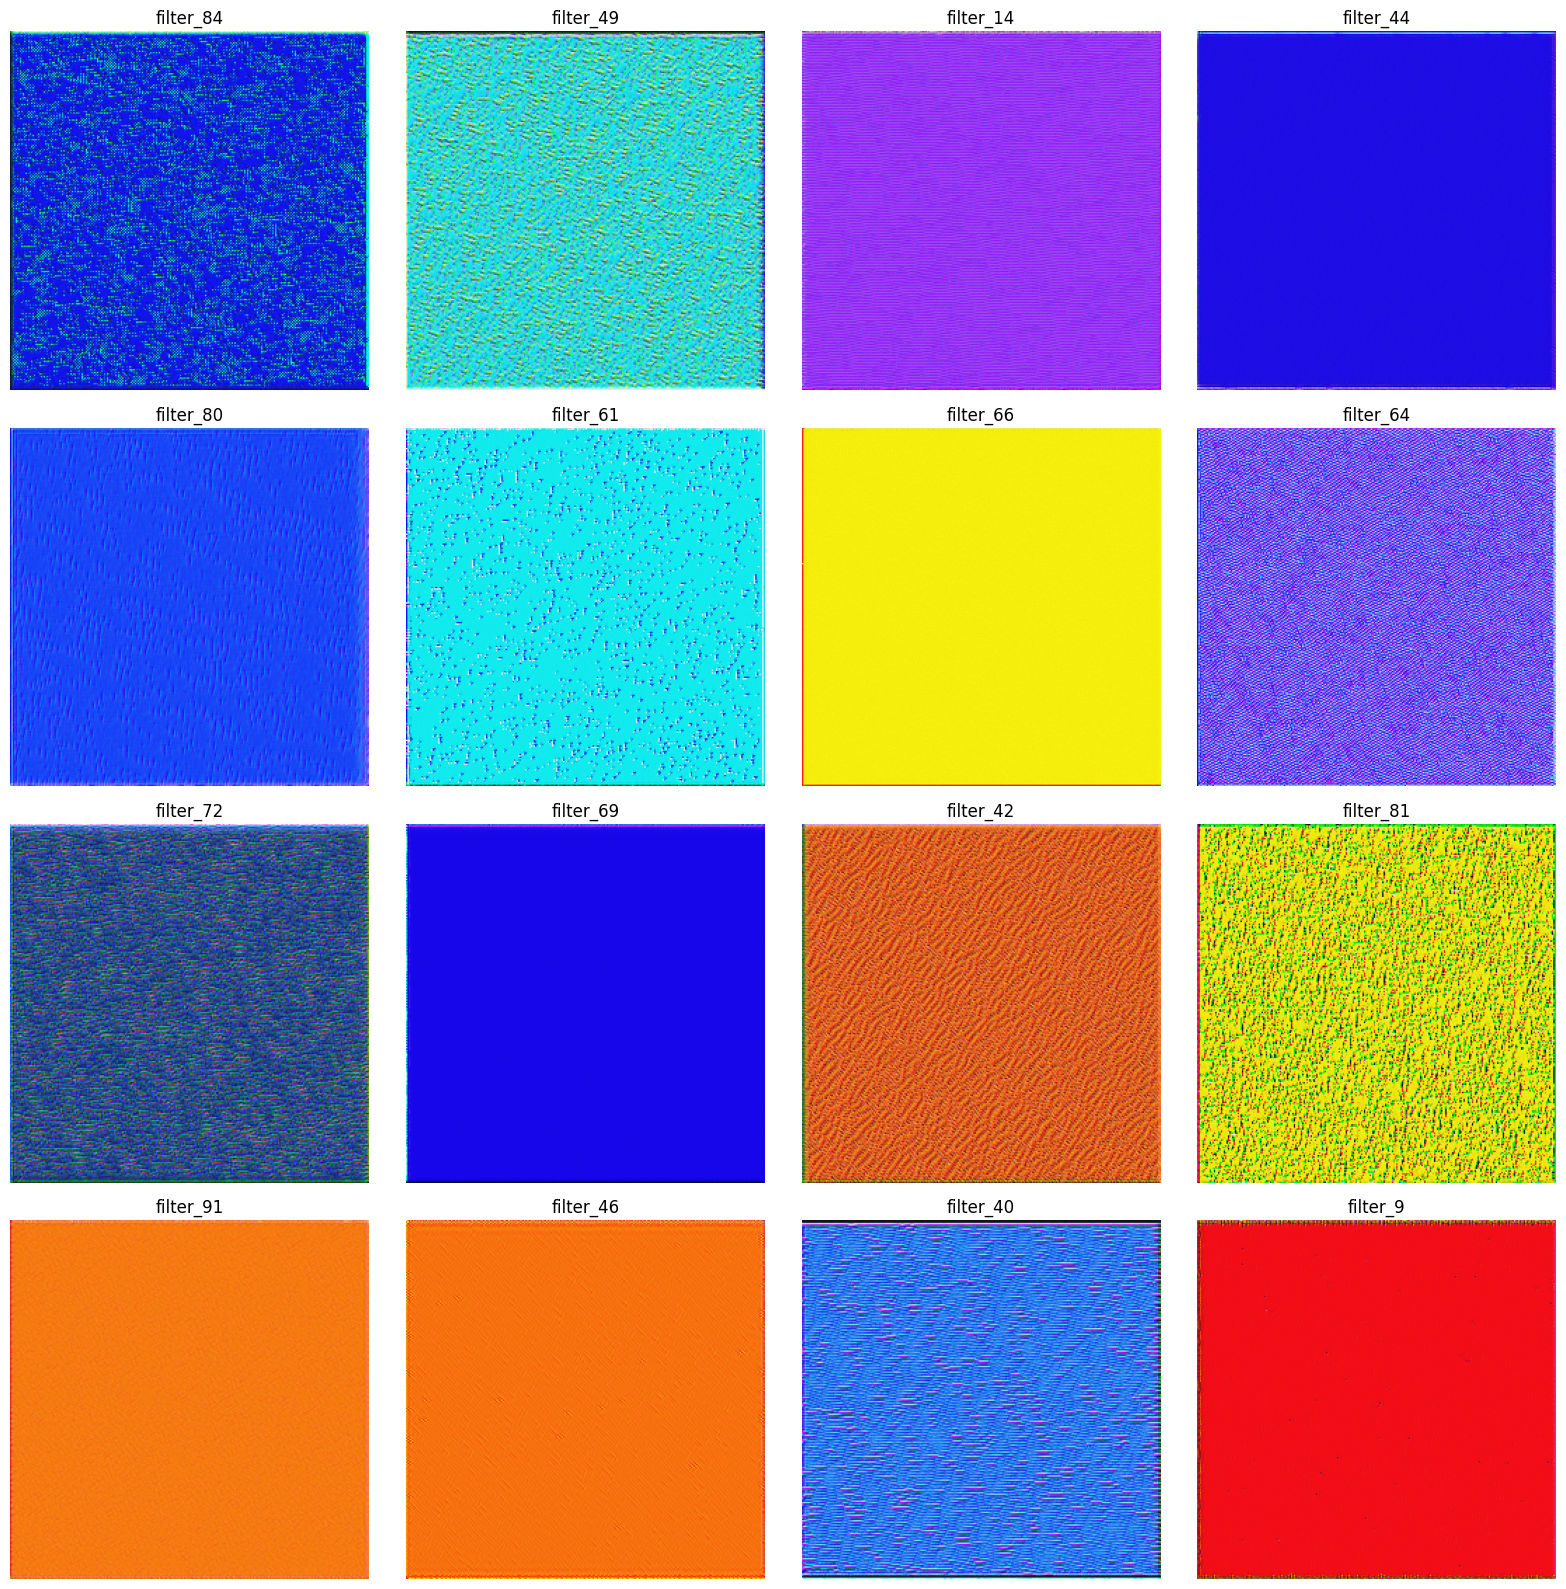

In [93]:
draw_imgs(
    imgs, 
    titles,
    n_cols=4,
    size=4
)

# Таблица с результатами

| Эксперимент (60 эпох) | train rmse | test rmse |
| :--- | :---: | :---: |
| **EfficientNet B0 (5.8M)** (разморозка слоёв features 6-8) + аугментация + AdamW + ReduceLROnPlateau | 0.02094 | 0.02335 |
| **EfficientNet B3 (12.7M)** (без разморозки feature слоёв) + AdamW + без аугментации + LR Scheduler | 0.03916 | 0.03462 |
| **Custom model (151.5M)** + Adam + BatchNorm + CosineAnnealingLR | 0.04398 | 0.05002 |
| **Custom model (151.5M)** + SGD (momentum = 0.9) без Dropout, без BatchNorm, без LRScheduler | 0.03461 | 0.03504 |
| **Custom model (151.5M)** + Adam без Dropout, без BatchNorm, без LRScheduler | 0.02111 | 0.02876 |

Лучше всего себя показала предобученная модель **EfficienNet B0 с размороженными feature слоями (6-8 блоки)**, **RandomPerspective** аугментацией, **AdamW** и **ReduceLROnPlateau**. Эта модель также является наиболее эффективной по числу параметров - **5.8M**. 

Среди кастомных моделей лучше всего себя показала модель, обученная с помощью **Adam, без Dropout, без BatchNorm, без LRScheduler**. Её метрики наиболее близки к предыдущей модели, однако число параметров у неё в **26 раз больше**